In [1]:
import itertools
import numpy as np
import pandas as pd
import seaborn as sbn
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
import localcider
from localcider.sequenceParameters import SequenceParameters
import re
import math
import scipy
from scipy.stats import ks_2samp
from matplotlib.patches import Rectangle
import pathlib
from matplotlib import font_manager
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from scipy.stats import fisher_exact

def bh_correction(pvals):
    """Benjamini-Hochberg FDR correction (returns adjusted p-values)."""
    pvals = np.array(pvals)
    n = len(pvals)
    order = np.argsort(pvals)
    ranks = np.empty(n, dtype=int)
    ranks[order] = np.arange(1, n + 1)
    adjusted = np.minimum(1.0, pvals * n / ranks)
    # Enforce monotonicity (cumulative minimum from the largest rank down)
    for i in order[::-1]:
        if i < n - 1:
            adjusted[order[np.where(order == i)[0][0] - 1]] = min(
                adjusted[order[np.where(order == i)[0][0] - 1]],
                adjusted[i]
            )
    return np.clip(adjusted, 0, 1)



# Setup the fonts
fonts_path = pathlib.Path.home().joinpath('fonts') # i.e. `~/fonts` (update as needed)
font_filename = 'ARIAL.TTF'
font_path = fonts_path.joinpath(font_filename)
print(font_path)

font_manager.fontManager.addfont(str(font_path))
prop = font_manager.FontProperties(fname=font_path)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
plt.rcParams['pdf.fonttype'] = 42 # Makes text editiable
plt.rcParams['ps.fonttype'] = 42

COLOR_MAP = dict()
COLOR_MAP['A']         = '#8c8c8c'
COLOR_MAP['CHNQST']    = '#077a15'
COLOR_MAP['DE']        = '#e23a36'
COLOR_MAP['FWY']       = '#f58220'
COLOR_MAP['G']         = '#86bd8d'
COLOR_MAP['ILMV']      = '#231f20'
COLOR_MAP['KR']        = '#1725c2'
COLOR_MAP['P']         = '#c25fc9'


# Using the global color map, we convert the colormap of amino acid
# groups, to a map against individual amino acids. This
# serves as our internal color map which is used for styling.
aacolor_map=dict()
for amino_acids in COLOR_MAP:
    for amino_acid in amino_acids:
        aacolor_map[amino_acid] = COLOR_MAP[amino_acids]

/Users/magalhae/fonts/ARIAL.TTF


In [2]:
IDR_df = pd.read_csv("Hsapien_IDRs_ftl100aa.fullseq.out_dist_matrix.csv.gz")
print(IDR_df.info())
IDR_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 10371 entries, 0 to 10370
Data columns (total 32 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   IDR_ID      10371 non-null  str    
 1   UniprotID   10371 non-null  str    
 2   cluster_0   10371 non-null  float64
 3   cluster_1   10371 non-null  float64
 4   cluster_2   10371 non-null  float64
 5   cluster_3   10371 non-null  float64
 6   cluster_4   10371 non-null  float64
 7   cluster_5   10371 non-null  float64
 8   cluster_6   10371 non-null  float64
 9   cluster_7   10371 non-null  float64
 10  cluster_8   10371 non-null  float64
 11  cluster_9   10371 non-null  float64
 12  cluster_10  10371 non-null  float64
 13  cluster_11  10371 non-null  float64
 14  cluster_12  10371 non-null  float64
 15  cluster_13  10371 non-null  float64
 16  cluster_14  10371 non-null  float64
 17  cluster_15  10371 non-null  float64
 18  cluster_16  10371 non-null  float64
 19  cluster_17  10371 non-null  float64


,IDR_ID,UniprotID,cluster_0,cluster_1,cluster_2,cluster_3,cluster_4,cluster_5,cluster_6,cluster_7,...,cluster_20,cluster_21,cluster_22,cluster_23,cluster_24,cluster_25,cluster_26,cluster_27,cluster_28,cluster_29
0,A0A0J9YXV3_IDR_1,A0A0J9YXV3,53.074100,69.339263,92.866347,53.685445,56.290970,92.898868,40.440279,114.984883,...,54.705648,80.685022,62.023698,89.441531,45.561131,43.628376,103.132329,38.382817,35.241911,41.912836
1,A6NGW2_IDR_1,A6NGW2,106.429424,64.346694,101.814967,88.746187,96.496202,125.164450,78.175394,160.774459,...,95.093182,95.746907,141.085195,157.907231,90.420069,94.038258,171.530446,81.031541,98.955480,83.146591
2,A6NIY4_IDR_1,A6NIY4,85.135719,89.289728,80.422646,57.318891,77.137128,47.297726,92.925704,64.949860,...,97.485851,123.292560,139.609693,77.714278,89.707037,69.652407,102.775577,90.615750,103.202574,85.746689
3,C4AMC7_IDR_1,C4AMC7,74.201999,58.125702,60.272779,58.640874,71.874779,40.648081,73.073160,93.792130,...,79.047278,94.627686,109.605287,85.230240,71.039682,62.665805,117.766144,69.612114,89.702076,74.649913
4,O00165_IDR_1,O00165,111.668358,124.312195,86.590082,104.095794,121.381411,131.034320,124.309125,123.949629,...,144.830099,143.660507,196.742420,159.034859,126.824530,135.022145,149.430839,133.262221,113.898516,123.290961


In [3]:
Liver_Nucleoli = pd.read_csv("./Lists/Liver_Nucleoli.tsv.gz")
HepG2_Nucleoli = pd.read_csv("./Lists/HepG2_Nucleoli.tsv.gz")
HCT116_Nucleoli = pd.read_csv("./Lists/HCT116_Nucleoli.tsv.gz")
HCT116_NSpeckle = pd.read_csv("./Lists/HCT116_NSpeckle.tsv.gz")

In [4]:

# 2. Filter the dataframe
# Replace 'UniProtID' with your actual ID column name
HCT116_Nucleoli_flt = IDR_df[IDR_df['UniprotID'].isin(HCT116_Nucleoli["UniprotID"])]
HepG2_Nucleoli_flt = IDR_df[IDR_df['UniprotID'].isin(HepG2_Nucleoli["UniprotID"])]
Liver_Nucleoli_flt = IDR_df[IDR_df['UniprotID'].isin(Liver_Nucleoli["UniprotID"])]
HCT116_NSpeckle_flt = IDR_df[IDR_df['UniprotID'].isin(HCT116_NSpeckle["UniprotID"])]


In [15]:
RBP_HS = pd.read_csv("High_confidence_human_RBPs.csv.gz")
RBP_HS.info()

RBP_HS_list = set(RBP_HS['Uniprot_ID'])
print(len(RBP_HS_list))

<class 'pandas.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Uniprot_ID               2018 non-null   str    
 1   RBP2GO_Score             2018 non-null   float64
 2   Composite_Score          2018 non-null   float64
 3   has_RBD                  2018 non-null   str    
 4   RBDs_nb                  2018 non-null   int64  
 5   RBDs_content_fraction    2018 non-null   float64
 6   has_fam_ID               2018 non-null   str    
 7   has_IDR                  2018 non-null   str    
 8   IDR_content_fraction     2018 non-null   float64
 9   Nb_Datasets              2018 non-null   int64  
 10  Listing_Count            2018 non-null   int64  
 11  AVG10_Int_Listing_Count  2018 non-null   float64
 12  Domain_score             2018 non-null   int64  
 13  RBP_status               2018 non-null   str    
 14  has_annot                2018 non-n

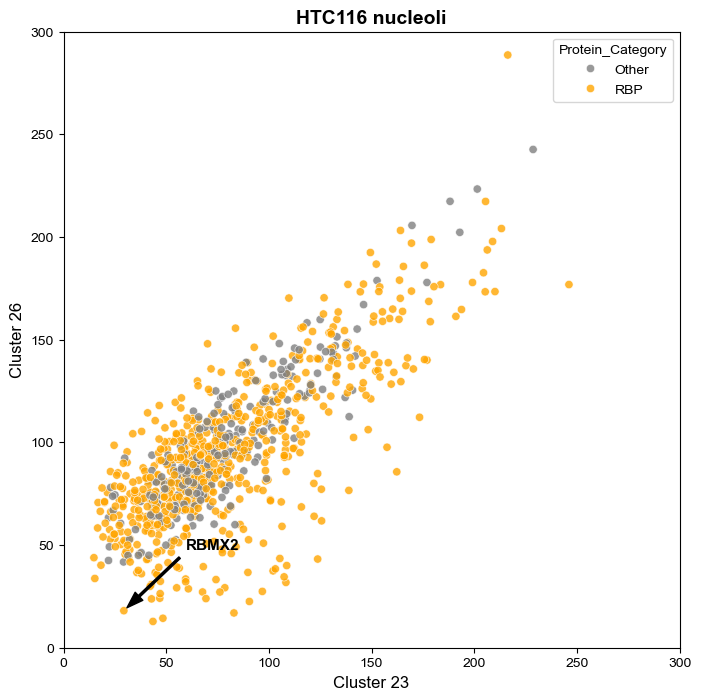

In [21]:
# 1. Create a new category column based on your RBP_HS_list
# Using a lambda function or np.where are both great ways to do this.
HCT116_Nucleoli_flt['Protein_Category'] = HCT116_Nucleoli_flt['UniprotID'].apply(
    lambda x: 'RBP' if x in RBP_HS_list else 'Other'
)

# 2. Set the figure size to be squared (e.g., 8x8)
plt.figure(figsize=(8, 8))

# 3. Create the scatterplot
sbn.scatterplot(
    data=HCT116_Nucleoli_flt, 
    x='cluster_23', 
    y='cluster_26',
    hue='Protein_Category',
    palette={'RBP': 'orange', 'Other': 'grey'}, # Assign colors
    alpha=0.8 # Slight transparency to see overlapping points better
)


# Find the row where UniprotID is 'Q9Y388'
target_protein = HCT116_Nucleoli_flt[HCT116_Nucleoli_flt['UniprotID'] == 'Q9Y388']

# Make sure the protein actually exists in the filtered data before trying to plot it
if not target_protein.empty:
    target_x = target_protein['cluster_23'].values[0]
    target_y = target_protein['cluster_26'].values[0]
    
    # Add the text and arrow
    plt.annotate(
        'RBMX2', 
        xy=(target_x, target_y),             # The coordinate to point the arrow at
        xytext=(target_x + 30, target_y + 30), # The coordinate for the text label (offset by 30)
        arrowprops=dict(
            facecolor='black',               # Color of the arrow
            shrink=0.05,                     # Leaves a tiny gap between arrow and point
            width=1.5,                       # Thickness of the arrow line
            headwidth=8                      # Width of the arrowhead
        ),
        fontsize=11,
        fontweight='bold',
        color='black'
    )




# 4. Set the X and Y axis limits from 0 to 300
plt.xlim(0, 300)
plt.ylim(0, 300)

plt.title('HTC116 nucleoli', fontsize=14, fontweight='bold')
plt.xlabel('Cluster 23', fontsize=12)
plt.ylabel('Cluster 26', fontsize=12)

# 5. Force the plot area to be perfectly square
plt.gca().set_aspect('equal', adjustable='box')

plt.savefig('HTC116_Nucleoli_centromer_scaterplot.pdf', format='pdf', bbox_inches='tight')

plt.show()

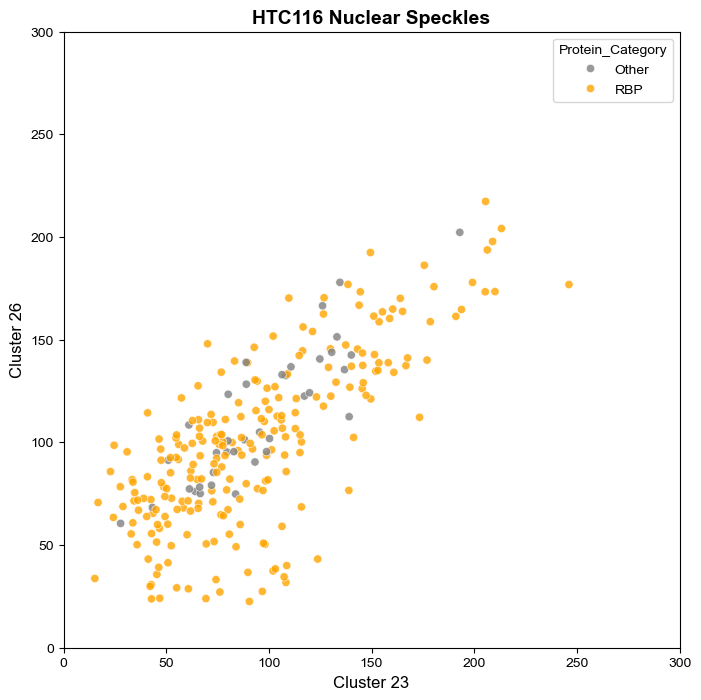

In [20]:
# 1. Create a new category column based on your RBP_HS_list
# Using a lambda function or np.where are both great ways to do this.
HCT116_NSpeckle_flt['Protein_Category'] = HCT116_NSpeckle_flt['UniprotID'].apply(
    lambda x: 'RBP' if x in RBP_HS_list else 'Other'
)

# 2. Set the figure size to be squared (e.g., 8x8)
plt.figure(figsize=(8, 8))

# 3. Create the scatterplot
sbn.scatterplot(
    data=HCT116_NSpeckle_flt, 
    x='cluster_23', 
    y='cluster_26',
    hue='Protein_Category',
    palette={'RBP': 'orange', 'Other': 'grey'}, # Assign colors
    alpha=0.8 # Slight transparency to see overlapping points better
)


# 4. Set the X and Y axis limits from 0 to 300
plt.xlim(0, 300)
plt.ylim(0, 300)

plt.title('HTC116 Nuclear Speckles', fontsize=14, fontweight='bold')
plt.xlabel('Cluster 23', fontsize=12)
plt.ylabel('Cluster 26', fontsize=12)

# 5. Force the plot area to be perfectly square
plt.gca().set_aspect('equal', adjustable='box')

plt.savefig('HTC116_Nuclear_Speckles_centromer_scaterplot.pdf', format='pdf', bbox_inches='tight')

plt.show()